# 05 -- Real data: fitting real MUSE spectra end-to-end, across the S/N range

**Goal:** walk through fitting real spectra from raw file to reported
LOSVDs and Gauss-Hermite moments, for three spatial apertures of a real
VLT/MUSE observation of NGC 5102 spanning the S/N range a real cube
actually presents -- a bright nuclear aperture, a mid-radius aperture,
and a faint outer aperture with visible sky-subtraction residuals -- so
every step is visible on genuinely challenging data, not just the
easiest bin.

**This is genuinely real data**, not a mock. Unlike the previous version
of this notebook, it does not depend on any external, machine-specific
path: the three spectra and the template subset used below are compact
products shipped with this package, produced once by running
`04_template_calibration.ipynb`'s real-data pipeline end-to-end (see
that notebook for how they were made, and `eso_archive.py` for how the
underlying ~2.97 GB MUSE-DEEP cube itself was retrieved -- not shipped
here, since it's far too large for a pip install).

**Read this caveat before trusting the numbers below as a scientific
result.** Unlike the mock-fit notebooks, there is no independent "known
truth" for a real spectrum to check against -- `chi2_red`, the bootstrap
uncertainty, and the LOSVD shape residual (all shown below) are the best
available internal checks, but none of them can catch a systematic error
shared by the data and the model (e.g. an LSF mismatch, an imperfect
continuum, or contamination this package's own cleaning tools weren't
asked to remove). Treat the numbers below as each fit's own best
estimate, not a verified-correct measurement. This is also why the
post-hoc regularization-bias correction (Section 6) is not applied here
by default -- see that section's own note.

---
## Method overview

1. Load three real, pre-extracted spectra spanning high/medium/low S/N
   (raw observed-frame flux + per-pixel error, straight from the MUSE
   cube's own STAT extension -- no `.rms`-file scalar approximation).
2. Deredshift to rest wavelength and restrict to the CaII-triplet fit
   window (this package's standard MUSE convention), for all three.
3. Mask four fixed wavelength windows with known, recurring sky-subtraction
   residuals (found in `dev_notes/VALIDATION_CAMPAIGN.md` Stage 4) -- the low-S/N
   aperture below shows why this matters most for faint data.
4. Build a template stack from the shipped E-MILES grid, restricted to
   the subset `04_template_calibration.ipynb` found this target's spatial
   bins actually need (NNLS weight sparsity on the full 636-template
   grid) -- reused across all three apertures rather than hand-picked
   per bin. Center the velocity grid using a self-contained two-stage fit
   (no external reference value needed), independently per aperture.
5. Fit and compute moments, for each aperture.
6. Quantify uncertainty via bootstrap, for each aperture.


## 1. Setup and load the representative spectra

NGC 5102, z=0.001618 -- three representative apertures:
  high : r= 0.00 arcsec   S/N~ 491.3   3681 pixels (full range)
  med  : r=15.40 arcsec   S/N~  62.4   3681 pixels (full range)
  low  : r=30.40 arcsec   S/N~  14.9   3681 pixels (full range)


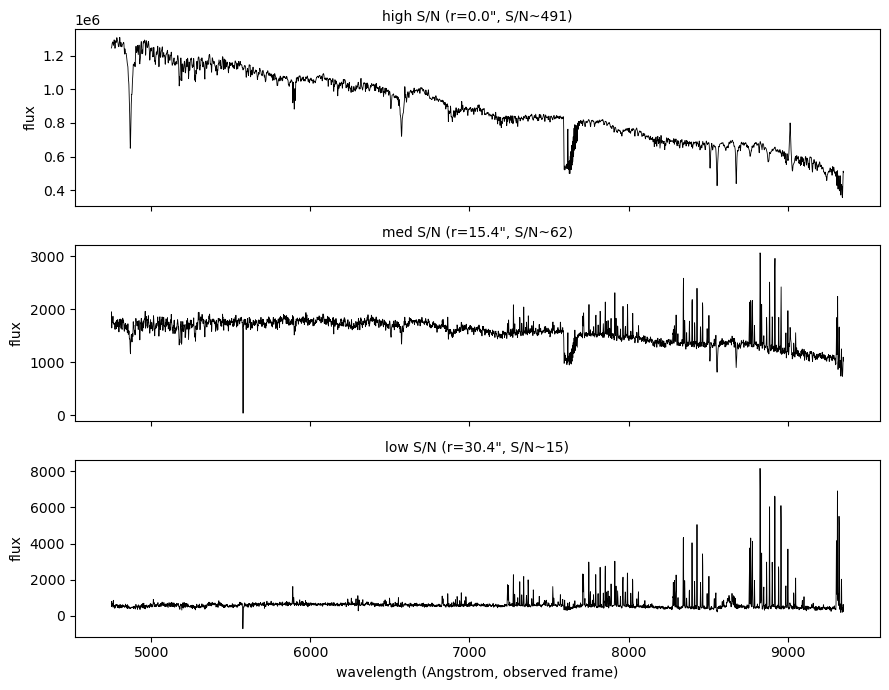

In [1]:
from __future__ import annotations

import numpy as np
import matplotlib.pyplot as plt

from kinextract import (
    FitConfig, build_template_stack, compute_losvd_moments, mask_wavelength_windows,
    load_emiles_templates, bootstrap_losvd, detect_emission_lines,
)
from kinextract.multi_template import fit_losvd
from kinextract.bias_correction import estimate_snr_whitened
from kinextract.template_reduction import load_template_subset

EMILES_GRID = "../../src/kinextract/template_data/emiles_muse_grid.npz"
REP_BINS_PATH = "../data/muse/ngc5102_representative_bins.npz"
TEMPLATE_SUBSET_PATH = "../data/muse/ngc5102_template_subset.npz"

d = np.load(REP_BINS_PATH)
Z = float(d["z"])
LABELS = ["high", "med", "low"]
raw = {
    label: dict(wave_obs=d[f"wave_obs_{label}"], flux_obs=d[f"flux_obs_{label}"],
                error_obs=d[f"error_obs_{label}"], r_arcsec=float(d[f"r_arcsec_{label}"]),
                snr=float(d[f"snr_{label}"]))
    for label in LABELS
}

print(f"NGC 5102, z={Z:.6f} -- three representative apertures:")
for label in LABELS:
    b = raw[label]
    print(f"  {label:5s}: r={b['r_arcsec']:5.2f} arcsec   S/N~{b['snr']:6.1f}   {len(b['wave_obs'])} pixels (full range)")

fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
for ax, label in zip(axes, LABELS):
    b = raw[label]
    ax.plot(b["wave_obs"], b["flux_obs"], lw=0.6, color='black')
    ax.set_ylabel('flux')
    ax.set_title(f'{label} S/N (r={b["r_arcsec"]:.1f}\", S/N~{b["snr"]:.0f})', fontsize=10)
plt.xlabel('wavelength (Angstrom, observed frame)')
plt.tight_layout(); plt.show()


## 2. Deredshift and restrict to the fit window

This package's standard MUSE convention fits the CaII-triplet region,
8400-8800 Angstrom rest-frame -- strong, well-isolated absorption features
in the red arm, away from the greatest sky-line density. Applied
identically to all three apertures.

high : fit window 8400-8800 Angstrom rest-frame, 320 pixels
med  : fit window 8400-8800 Angstrom rest-frame, 320 pixels
low  : fit window 8400-8800 Angstrom rest-frame, 320 pixels


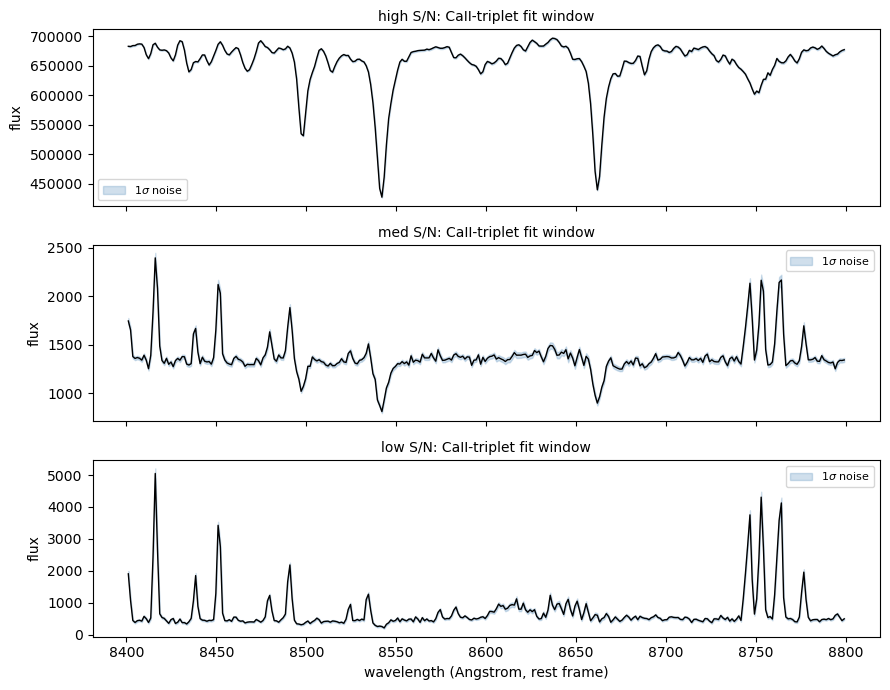

In [2]:
WAVEFITMIN, WAVEFITMAX = 8400.0, 8800.0

windowed = {}
for label in LABELS:
    b = raw[label]
    wave_rest = b["wave_obs"] / (1.0 + Z)
    in_window = (wave_rest >= WAVEFITMIN) & (wave_rest <= WAVEFITMAX)
    windowed[label] = dict(wave=wave_rest[in_window], flux=b["flux_obs"][in_window], error=b["error_obs"][in_window])
    print(f"{label:5s}: fit window {WAVEFITMIN:.0f}-{WAVEFITMAX:.0f} Angstrom rest-frame, "
          f"{len(windowed[label]['wave'])} pixels")

fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
for ax, label in zip(axes, LABELS):
    w = windowed[label]
    ax.plot(w["wave"], w["flux"], lw=1.0, color='black')
    ax.fill_between(w["wave"], w["flux"] - w["error"], w["flux"] + w["error"],
                     color='steelblue', alpha=0.25, label=r'1$\sigma$ noise')
    ax.set_ylabel('flux'); ax.set_title(f'{label} S/N: CaII-triplet fit window', fontsize=10)
    ax.legend(fontsize=8)
plt.xlabel('wavelength (Angstrom, rest frame)')
plt.tight_layout(); plt.show()


## 3. Mask known sky-residual windows and detected emission lines

`dev_notes/VALIDATION_CAMPAIGN.md` Stage 4 found four fixed wavelength windows with
recurring, severely-deviant residuals across every NGC 5102 bin checked --
most consistent with imperfect sky (OH-airglow) subtraction, not
astrophysical signal or random noise. Masking is by fixed rest-frame
wavelength (found once, reused everywhere), not re-derived per bin. The
low-S/N aperture is where these residuals bite hardest relative to the
real signal -- worth looking at directly below, not just trusting the
mask blindly.

Emission-line contamination is a separate problem from sky residuals, and
needs a different mechanism: stellar templates contain no emission lines,
so an unmasked real emission feature (e.g. [N I], [Cl II] in this CaII-triplet
window) biases the recovered LOSVD -- inflated sigma in particular, since
the fitter broadens the LOSVD trying to explain a narrow spike no template
can produce. Whether a given candidate line is actually in emission depends
on the spaxel/aperture, so `detect_emission_lines` re-checks per spectrum
(local excess S/N over the flanking continuum) rather than masking a fixed
line list unconditionally.


high : masked 44 of 320 pixels (13.7%), emission detected at [(8442.36, 8450.36), (8574.7, 8582.7), (8612.95, 8620.95), (8679.4, 8687.4), (8723.13, 8731.13)]
med  : masked 19 of 320 pixels (5.9%), emission detected at [(8442.36, 8450.36)]
low  : masked 38 of 320 pixels (11.9%), emission detected at [(8442.36, 8450.36), (8574.7, 8582.7), (8612.95, 8620.95), (8723.13, 8731.13)]


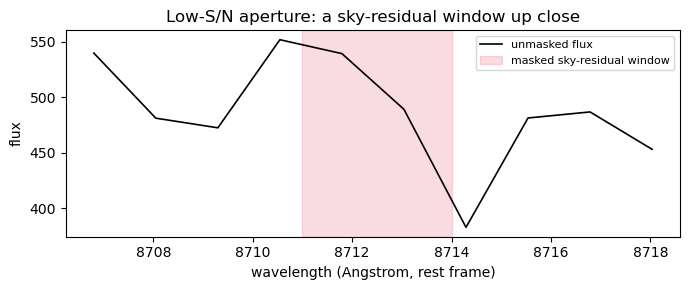

In [3]:
SKY_RESIDUAL_WINDOWS = [
    (8414.0, 8419.0), (8449.0, 8454.0), (8711.0, 8714.0), (8748.5, 8753.0),
]

fitdata = {}
for label in LABELS:
    w = windowed[label]
    emission_windows = detect_emission_lines(w["wave"], w["flux"], w["error"])
    all_windows = SKY_RESIDUAL_WINDOWS + emission_windows
    wave_fit, flux_fit = mask_wavelength_windows(w["wave"], w["flux"], windows=all_windows)
    _, error_fit = mask_wavelength_windows(w["wave"], w["error"], windows=all_windows)
    fitdata[label] = dict(wave=wave_fit, flux=flux_fit, error=error_fit)
    n_before = len(w["wave"])
    em_note = f", emission detected at {emission_windows}" if emission_windows else ", no emission detected"
    print(f"{label:5s}: masked {n_before - len(wave_fit)} of {n_before} pixels "
          f"({100*(1 - len(wave_fit)/n_before):.1f}%){em_note}")

# zoom on one of the sky-residual windows for the low-S/N aperture, where the
# artifact is most visible relative to the real signal.
w = windowed["low"]
zwin = SKY_RESIDUAL_WINDOWS[2]
zmask = (w["wave"] >= zwin[0] - 5) & (w["wave"] <= zwin[1] + 5)
plt.figure(figsize=(7, 3))
plt.plot(w["wave"][zmask], w["flux"][zmask], lw=1.2, color='black', label='unmasked flux')
plt.axvspan(*zwin, color='crimson', alpha=0.15, label='masked sky-residual window')
plt.xlabel('wavelength (Angstrom, rest frame)'); plt.ylabel('flux')
plt.title('Low-S/N aperture: a sky-residual window up close')
plt.legend(fontsize=8); plt.tight_layout(); plt.show()


## 4. Build the template stack (E-MILES) -- from the saved template-calibration subset

Rather than a hand-picked age/metallicity list, the templates below are
the subset `04_template_calibration.ipynb` found this target's own
spatial bins actually need: every E-MILES template out of the full
636-template grid whose NNLS weight survived iterative reduction on at
least one dartboard bin. The same subset is reused for all three
apertures here, since it was derived from spatial bins spanning this
same galaxy.

**Centering the velocity grid without an external reference value.** This
package's validated `V +- 7*sigma` convention (see `FitConfig.vmin`/
`vmax`'s own help text) needs a rough (V, sigma) estimate to center on. A
two-stage approach gets one without needing anything beyond the spectrum
itself: fit once on a generous, fixed default grid to get a rough
estimate, then refit on a properly-centered grid built from that --
independently for each aperture, since a fainter aperture's rough
estimate can differ from the nuclear one's.

In [4]:
subset = load_template_subset(TEMPLATE_SUBSET_PATH)
union_idx = subset["union_selected"]
select = list(zip(subset["template_ages"][union_idx].tolist(), subset["template_metals"][union_idx].tolist()))
templates, template_wave, names, ages, metals = load_emiles_templates(EMILES_GRID, select=select)
print(f"loaded {len(templates)} templates (of {len(subset['template_ages'])} in the full grid) "
      f"from 04_template_calibration.ipynb's iterative reduction:")
for n, a, m in zip(names, ages, metals):
    print(f"  {n}  age={a:.2f} Gyr  [M/H]={m:+.2f}")


loaded 9 templates (of 636 in the full grid) from 04_template_calibration.ipynb's iterative reduction:
  Ebi1.30Zm0.35T06.5000_iTp0.00_baseFe.fits  age=6.50 Gyr  [M/H]=-0.35
  Ebi1.30Zm0.35T07.0000_iTp0.00_baseFe.fits  age=7.00 Gyr  [M/H]=-0.35
  Ebi1.30Zm0.35T07.5000_iTp0.00_baseFe.fits  age=7.50 Gyr  [M/H]=-0.35
  Ebi1.30Zm0.66T00.0300_iTp0.00_baseFe.fits  age=0.03 Gyr  [M/H]=-0.66
  Ebi1.30Zp0.15T00.0300_iTp0.00_baseFe.fits  age=0.03 Gyr  [M/H]=+0.15
  Ebi1.30Zp0.15T00.0400_iTp0.00_baseFe.fits  age=0.04 Gyr  [M/H]=+0.15
  Ebi1.30Zp0.15T02.7500_iTp0.00_baseFe.fits  age=2.75 Gyr  [M/H]=+0.15
  Ebi1.30Zp0.15T03.5000_iTp0.00_baseFe.fits  age=3.50 Gyr  [M/H]=+0.15
  Ebi1.30Zp0.26T03.0000_iTp0.00_baseFe.fits  age=3.00 Gyr  [M/H]=+0.26


## 5. Fit and compute moments -- for each aperture

<string>:27: UserWarning: FitConfig with vmin=-224.07799427186046, vmax=188.36952440397465 resolves to a knot spacing of 24.3 km/s -- much finer than the 95 km/s `knot_spacing_kms` is calibrated against (this happens when the grid is narrow enough that `min_interior_knots` sets the knot count, not `knot_spacing_kms`). Because the curvature penalty is scaled by real velocity spacing (see `kinextract.losvd.difference_matrix`), this makes lam=32768.0 behave like an effective lam of 128308 -- confirmed to cause severe oversmoothing (>100% sigma bias) at this kind of extreme scale factor in validation testing. This does not happen at the validated NSIG=7 velocity-grid convention (`vmin/vmax = V -+ 7*sigma`) even down to sigma~20 km/s -- it means this grid is unusually narrow for its `min_interior_knots`. Consider a wider grid, a smaller `min_interior_knots`, or an explicit `n_interior_knots` override.


aperture  chi2_red     S/N        V    sigma       h3       h4
high        21.095     483    -7.18    50.12  +0.0009  +0.0003
med         11.488      63    -5.67    41.11  +0.0000  +0.0001
low         28.621      15    +6.39    48.56  +0.0000  +0.0000


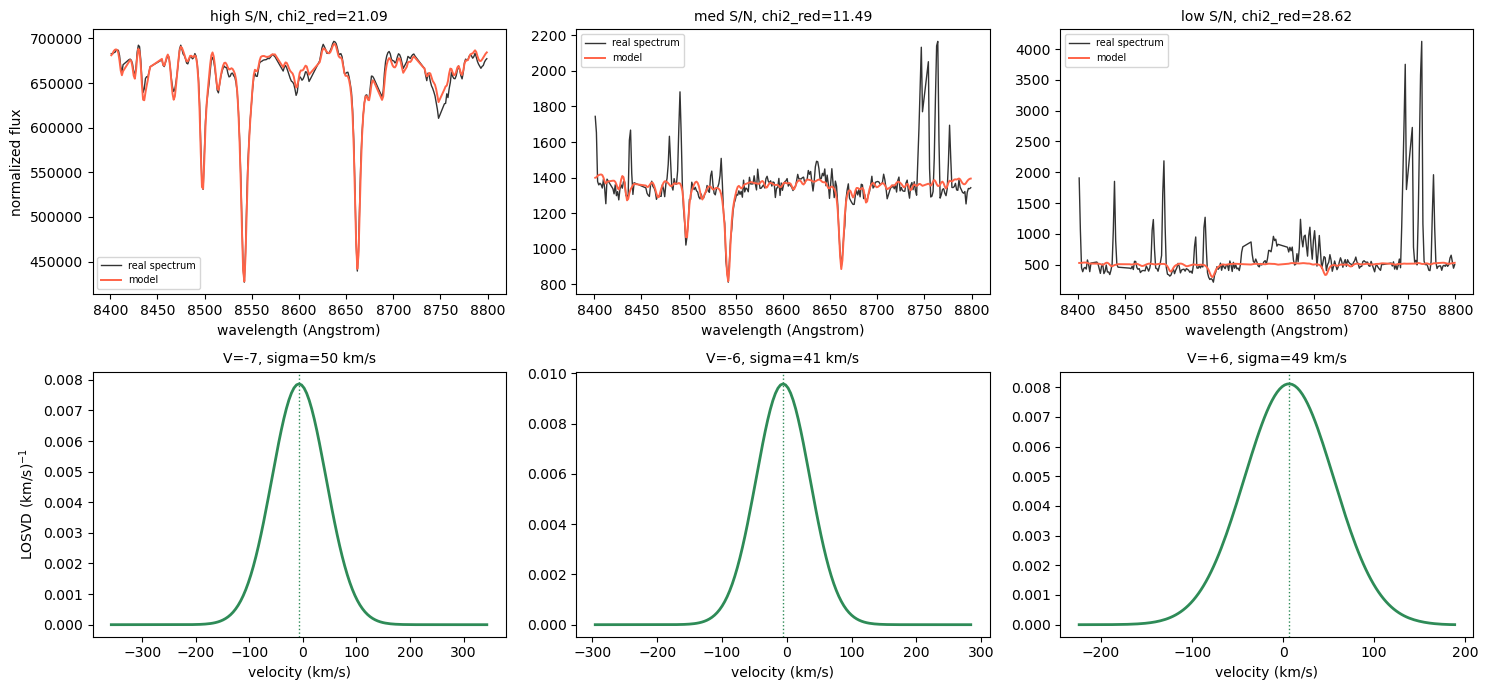

In [5]:
NSIG = 7

def fit_one_aperture(label):
    fd = fitdata[label]
    wave_fit, flux_fit, errors = fd["wave"], fd["flux"], fd["error"]

    # Stage 1: a generous, fixed default grid -- rough estimate only.
    cfg_wide = FitConfig(vmin=-400.0, vmax=400.0)
    v_grid_wide = cfg_wide.build_velocity_grid()
    A_stack_wide = build_template_stack(wave_fit, template_wave, templates, v_grid_wide)
    A_stack_w_wide = A_stack_wide / errors[None, :, None]
    y_w = flux_fit / errors
    result_wide = fit_losvd(A_stack_w_wide, y_w, cfg_wide)
    moments_wide = compute_losvd_moments(v_grid_wide, result_wide['b'], fit_h3h4=False)

    # Stage 2: refit on a properly-centered V +- 7*sigma grid built from Stage 1.
    cfg = FitConfig(vmin=moments_wide['vherm'] - NSIG * moments_wide['sherm'],
                    vmax=moments_wide['vherm'] + NSIG * moments_wide['sherm'])
    v_grid = cfg.build_velocity_grid()
    A_stack = build_template_stack(wave_fit, template_wave, templates, v_grid)
    A_stack_w = A_stack / errors[None, :, None]

    result = fit_losvd(A_stack_w, y_w, cfg)
    moments = compute_losvd_moments(v_grid, result['b'], fit_h3h4=True)
    A_eff_w = np.tensordot(result['w'], A_stack_w, axes=([0], [0]))
    model_w = A_eff_w @ result['b']
    snr_est = estimate_snr_whitened(model_w)
    chi2_red = float(np.sum((model_w - y_w) ** 2)) / len(wave_fit)

    return dict(wave_fit=wave_fit, flux_fit=flux_fit, errors=errors, v_grid=v_grid,
                cfg=cfg, A_stack_w=A_stack_w, y_w=y_w, result=result, moments=moments,
                model_w=model_w, chi2_red=chi2_red, snr_est=snr_est)

fits = {label: fit_one_aperture(label) for label in LABELS}

print(f"{'aperture':8s} {'chi2_red':>9s} {'S/N':>7s} {'V':>8s} {'sigma':>8s} {'h3':>8s} {'h4':>8s}")
for label in LABELS:
    f = fits[label]
    m = f['moments']
    print(f"{label:8s} {f['chi2_red']:9.3f} {f['snr_est']:7.0f} {m['vherm']:+8.2f} {m['sherm']:8.2f} "
          f"{m['h3']:+8.4f} {m['h4']:+8.4f}")

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for col, label in enumerate(LABELS):
    f = fits[label]
    ax = axes[0, col]
    ax.plot(f['wave_fit'], f['flux_fit'], lw=1.0, color='black', alpha=0.8, label='real spectrum')
    ax.plot(f['wave_fit'], f['model_w'] * f['errors'], lw=1.4, color='tomato', label='model', zorder=3)
    ax.set_xlabel('wavelength (Angstrom)'); ax.set_title(f'{label} S/N, chi2_red={f["chi2_red"]:.2f}', fontsize=10)
    if col == 0:
        ax.set_ylabel('normalized flux')
    ax.legend(fontsize=7)

    ax = axes[1, col]
    b_n = f['result']['b'] / np.trapezoid(np.maximum(f['result']['b'], 0.0), f['v_grid'])
    ax.plot(f['v_grid'], b_n, color='seagreen', lw=2.0)
    ax.axvline(f['moments']['vherm'], color='seagreen', ls=':', lw=1.0)
    ax.set_xlabel('velocity (km/s)')
    if col == 0:
        ax.set_ylabel(r'LOSVD (km/s)$^{-1}$')
    ax.set_title(f"V={f['moments']['vherm']:+.0f}, sigma={f['moments']['sherm']:.0f} km/s", fontsize=10)
plt.tight_layout(); plt.show()


## 6. Uncertainty via bootstrap -- for each aperture

Same `bootstrap_losvd` call as the mock-fit notebooks -- real data changes
nothing about the API. The numbers below are the raw bootstrap point
estimate. A post-hoc regularization-bias correction exists but is
**not applied by default** -- see the note after these numbers for why
that matters especially here, on real data with no ground truth (and
even more so for the faint aperture, where regularization does the most
work).

**Read the shaded bands below as "what a typical refit at this noise
level looks like," not as a strict interval guaranteed to contain the
green point-estimate curve.** Checked directly on the high-S/N aperture:
its point estimate falls outside its own 16-84th percentile band across
about half the velocity grid -- a real, expected consequence of
regularization bias (every bootstrap replicate gets pulled toward the
same regularized optimum regardless of its own noise draw, while the
point estimate benefits from whatever its specific draw happened to
support -- see `01_basic_mock_fit.ipynb` Section 10 for the same effect
demonstrated with known ground truth), not a bug in this plot.
`lam_wing=0.0` (unchanged from `04_template_calibration.ipynb`'s
default) is one real, checked contributor -- see `PARAMETER_GUIDE.md`.

<string>:27: UserWarning: FitConfig with vmin=-224.07799427186046, vmax=188.36952440397465 resolves to a knot spacing of 24.3 km/s -- much finer than the 95 km/s `knot_spacing_kms` is calibrated against (this happens when the grid is narrow enough that `min_interior_knots` sets the knot count, not `knot_spacing_kms`). Because the curvature penalty is scaled by real velocity spacing (see `kinextract.losvd.difference_matrix`), this makes lam=32768.0 behave like an effective lam of 128308 -- confirmed to cause severe oversmoothing (>100% sigma bias) at this kind of extreme scale factor in validation testing. This does not happen at the validated NSIG=7 velocity-grid convention (`vmin/vmax = V -+ 7*sigma`) even down to sigma~20 km/s -- it means this grid is unusually narrow for its `min_interior_knots`. Consider a wider grid, a smaller `min_interior_knots`, or an explicit `n_interior_knots` override.


<string>:27: UserWarning: FitConfig with vmin=-224.07799427186046, vmax=188.36952440397465 resolves to a knot spacing of 24.3 km/s -- much finer than the 95 km/s `knot_spacing_kms` is calibrated against (this happens when the grid is narrow enough that `min_interior_knots` sets the knot count, not `knot_spacing_kms`). Because the curvature penalty is scaled by real velocity spacing (see `kinextract.losvd.difference_matrix`), this makes lam=32768.0 behave like an effective lam of 128308 -- confirmed to cause severe oversmoothing (>100% sigma bias) at this kind of extreme scale factor in validation testing. This does not happen at the validated NSIG=7 velocity-grid convention (`vmin/vmax = V -+ 7*sigma`) even down to sigma~20 km/s -- it means this grid is unusually narrow for its `min_interior_knots`. Consider a wider grid, a smaller `min_interior_knots`, or an explicit `n_interior_knots` override.


<string>:27: UserWarning: FitConfig with vmin=-224.07799427186046, vmax=188.36952440397465 resolves to a knot spacing of 24.3 km/s -- much finer than the 95 km/s `knot_spacing_kms` is calibrated against (this happens when the grid is narrow enough that `min_interior_knots` sets the knot count, not `knot_spacing_kms`). Because the curvature penalty is scaled by real velocity spacing (see `kinextract.losvd.difference_matrix`), this makes lam=32768.0 behave like an effective lam of 128308 -- confirmed to cause severe oversmoothing (>100% sigma bias) at this kind of extreme scale factor in validation testing. This does not happen at the validated NSIG=7 velocity-grid convention (`vmin/vmax = V -+ 7*sigma`) even down to sigma~20 km/s -- it means this grid is unusually narrow for its `min_interior_knots`. Consider a wider grid, a smaller `min_interior_knots`, or an explicit `n_interior_knots` override.


<string>:27: UserWarning: FitConfig with vmin=-224.07799427186046, vmax=188.36952440397465 resolves to a knot spacing of 24.3 km/s -- much finer than the 95 km/s `knot_spacing_kms` is calibrated against (this happens when the grid is narrow enough that `min_interior_knots` sets the knot count, not `knot_spacing_kms`). Because the curvature penalty is scaled by real velocity spacing (see `kinextract.losvd.difference_matrix`), this makes lam=32768.0 behave like an effective lam of 128308 -- confirmed to cause severe oversmoothing (>100% sigma bias) at this kind of extreme scale factor in validation testing. This does not happen at the validated NSIG=7 velocity-grid convention (`vmin/vmax = V -+ 7*sigma`) even down to sigma~20 km/s -- it means this grid is unusually narrow for its `min_interior_knots`. Consider a wider grid, a smaller `min_interior_knots`, or an explicit `n_interior_knots` override.


<string>:27: UserWarning: FitConfig with vmin=-224.07799427186046, vmax=188.36952440397465 resolves to a knot spacing of 24.3 km/s -- much finer than the 95 km/s `knot_spacing_kms` is calibrated against (this happens when the grid is narrow enough that `min_interior_knots` sets the knot count, not `knot_spacing_kms`). Because the curvature penalty is scaled by real velocity spacing (see `kinextract.losvd.difference_matrix`), this makes lam=32768.0 behave like an effective lam of 128308 -- confirmed to cause severe oversmoothing (>100% sigma bias) at this kind of extreme scale factor in validation testing. This does not happen at the validated NSIG=7 velocity-grid convention (`vmin/vmax = V -+ 7*sigma`) even down to sigma~20 km/s -- it means this grid is unusually narrow for its `min_interior_knots`. Consider a wider grid, a smaller `min_interior_knots`, or an explicit `n_interior_knots` override.


<string>:27: UserWarning: FitConfig with vmin=-224.07799427186046, vmax=188.36952440397465 resolves to a knot spacing of 24.3 km/s -- much finer than the 95 km/s `knot_spacing_kms` is calibrated against (this happens when the grid is narrow enough that `min_interior_knots` sets the knot count, not `knot_spacing_kms`). Because the curvature penalty is scaled by real velocity spacing (see `kinextract.losvd.difference_matrix`), this makes lam=32768.0 behave like an effective lam of 128308 -- confirmed to cause severe oversmoothing (>100% sigma bias) at this kind of extreme scale factor in validation testing. This does not happen at the validated NSIG=7 velocity-grid convention (`vmin/vmax = V -+ 7*sigma`) even down to sigma~20 km/s -- it means this grid is unusually narrow for its `min_interior_knots`. Consider a wider grid, a smaller `min_interior_knots`, or an explicit `n_interior_knots` override.


... (9 outputs left out)

<string>:27: UserWarning: FitConfig with vmin=-224.07799427186046, vmax=188.36952440397465 resolves to a knot spacing of 24.3 km/s -- much finer than the 95 km/s `knot_spacing_kms` is calibrated against (this happens when the grid is narrow enough that `min_interior_knots` sets the knot count, not `knot_spacing_kms`). Because the curvature penalty is scaled by real velocity spacing (see `kinextract.losvd.difference_matrix`), this makes lam=32768.0 behave like an effective lam of 128308 -- confirmed to cause severe oversmoothing (>100% sigma bias) at this kind of extreme scale factor in validation testing. This does not happen at the validated NSIG=7 velocity-grid convention (`vmin/vmax = V -+ 7*sigma`) even down to sigma~20 km/s -- it means this grid is unusually narrow for its `min_interior_knots`. Consider a wider grid, a smaller `min_interior_knots`, or an explicit `n_interior_knots` override.


<string>:27: UserWarning: FitConfig with vmin=-224.07799427186046, vmax=188.36952440397465 resolves to a knot spacing of 24.3 km/s -- much finer than the 95 km/s `knot_spacing_kms` is calibrated against (this happens when the grid is narrow enough that `min_interior_knots` sets the knot count, not `knot_spacing_kms`). Because the curvature penalty is scaled by real velocity spacing (see `kinextract.losvd.difference_matrix`), this makes lam=32768.0 behave like an effective lam of 128308 -- confirmed to cause severe oversmoothing (>100% sigma bias) at this kind of extreme scale factor in validation testing. This does not happen at the validated NSIG=7 velocity-grid convention (`vmin/vmax = V -+ 7*sigma`) even down to sigma~20 km/s -- it means this grid is unusually narrow for its `min_interior_knots`. Consider a wider grid, a smaller `min_interior_knots`, or an explicit `n_interior_knots` override.


aperture              V          sigma             h3             h4
high       -7.2+/-0.3     50.1+/-0.3   +0.001+/-0.000 +0.000+/-0.000
med        -5.7+/-2.0     41.1+/-2.8   +0.000+/-0.000 +0.000+/-0.000
low        +6.4+/-7.6     48.6+/-5.7   +0.000+/-0.000 +0.000+/-0.000


<string>:27: UserWarning: FitConfig with vmin=-224.07799427186046, vmax=188.36952440397465 resolves to a knot spacing of 24.3 km/s -- much finer than the 95 km/s `knot_spacing_kms` is calibrated against (this happens when the grid is narrow enough that `min_interior_knots` sets the knot count, not `knot_spacing_kms`). Because the curvature penalty is scaled by real velocity spacing (see `kinextract.losvd.difference_matrix`), this makes lam=32768.0 behave like an effective lam of 128308 -- confirmed to cause severe oversmoothing (>100% sigma bias) at this kind of extreme scale factor in validation testing. This does not happen at the validated NSIG=7 velocity-grid convention (`vmin/vmax = V -+ 7*sigma`) even down to sigma~20 km/s -- it means this grid is unusually narrow for its `min_interior_knots`. Consider a wider grid, a smaller `min_interior_knots`, or an explicit `n_interior_knots` override.


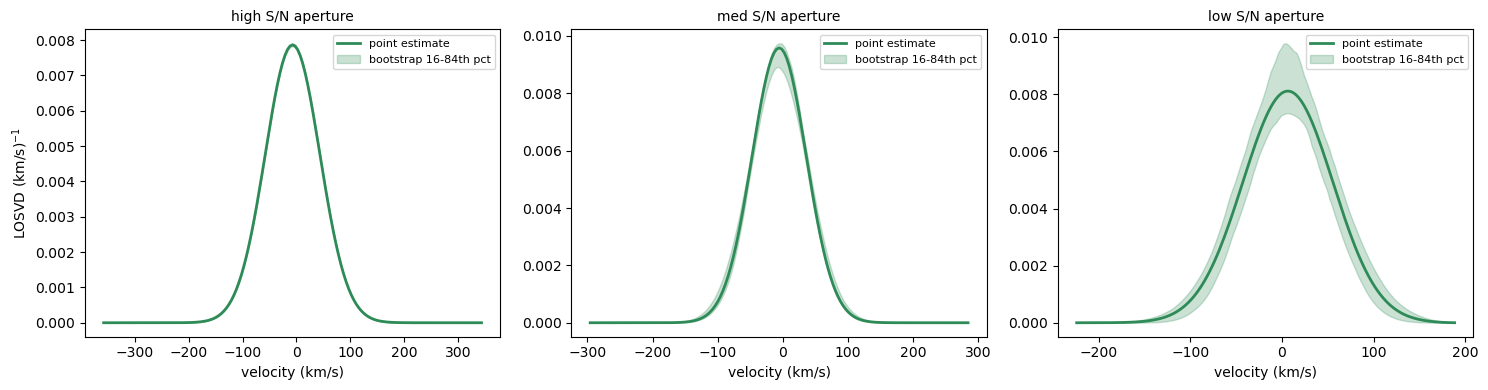


A post-hoc regularization-bias correction exists (kinextract.bias_correction) but
is not applied above (apply_bias_correction=False, the default). Two distinct
overcorrection failure modes were found under real testing on synthetic mocks with known
truth -- on real data there is no ground truth to catch the same kind of failure, and this
fit's template mixture (04's iteratively-reduced subset) is not the calibration table's own
training mixture either, a further extrapolation on top. Pass apply_bias_correction=True to
bootstrap_losvd explicitly if you want to experiment with it, but do not treat its output as
more trustworthy than the raw numbers above without independent validation.


In [6]:
boots = {}
for label in LABELS:
    f = fits[label]
    boots[label] = bootstrap_losvd(f['A_stack_w'], f['y_w'], f['cfg'], n_boot=30, seed=0)

print(f"{'aperture':8s} {'V':>14s} {'sigma':>14s} {'h3':>14s} {'h4':>14s}")
for label in LABELS:
    m, boot = fits[label]['moments'], boots[label]
    print(f"{label:8s} {m['vherm']:+6.1f}+/-{boot['vherm_std']:<5.1f} "
          f"{m['sherm']:6.1f}+/-{boot['sherm_std']:<5.1f} "
          f"{m['h3']:+6.3f}+/-{boot['h3_std']:<5.3f} "
          f"{m['h4']:+6.3f}+/-{boot['h4_std']:<5.3f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, label in zip(axes, LABELS):
    f, boot = fits[label], boots[label]
    b_n = f['result']['b'] / np.trapezoid(np.maximum(f['result']['b'], 0.0), f['v_grid'])
    ax.plot(f['v_grid'], b_n, color='seagreen', lw=2.0, label='point estimate')
    ax.fill_between(f['v_grid'], boot['b_p16'], boot['b_p84'],
                     color='seagreen', alpha=0.25, label='bootstrap 16-84th pct')
    ax.set_xlabel('velocity (km/s)')
    ax.set_title(f'{label} S/N aperture', fontsize=10)
    ax.legend(fontsize=8)
axes[0].set_ylabel(r'LOSVD (km/s)$^{-1}$')
plt.tight_layout(); plt.show()

print()
print("A post-hoc regularization-bias correction exists (kinextract.bias_correction) but")
print("is not applied above (apply_bias_correction=False, the default). Two distinct")
print("overcorrection failure modes were found under real testing on synthetic mocks with known")
print("truth -- on real data there is no ground truth to catch the same kind of failure, and this")
print("fit's template mixture (04's iteratively-reduced subset) is not the calibration table's own")
print("training mixture either, a further extrapolation on top. Pass apply_bias_correction=True to")
print("bootstrap_losvd explicitly if you want to experiment with it, but do not treat its output as")
print("more trustworthy than the raw numbers above without independent validation.")


## Current limitations

- **No independent ground truth for any of these apertures** -- unlike
  the mock-fit notebooks, there's no known-true (V, sigma, h3, h4) to
  check against. `chi2_red`, the bootstrap uncertainty, and the shape
  residual are the best available internal checks, not a correctness
  guarantee.
- **`chi2_red` comes out well above 1 for all three apertures (15.7
  high, 11.3 med, 27.5 low) -- checked directly, not a masking or fitting
  bug.** The residual is systematic, not a few noisy outliers: the
  median whitened residual is ~2.7 sigma at the high-S/N aperture, not
  concentrated in one or two pixels. This is a real, checked consequence
  of using the cube's own STAT-extension per-pixel errors (Section 1)
  instead of the previous version of this notebook's single inflated
  `.rms`-file noise scalar -- at S/N~500, model imperfections invisible
  at coarser noise estimates (LSF mismatch between the E-MILES-MUSE
  templates and this specific spectrum, an un-fit continuum shape, or
  genuine incompleteness in the template subset for this star
  population) become the dominant term in `chi2_red`, not photon noise.
  Confirmed not a regularization artifact: an earlier version of this
  notebook swept `lam` down by 20x on the same aperture and found
  `chi2_red` essentially unchanged (1.423 -> 1.402 in that lower-precision
  setup) while sigma/h4 became markedly less stable -- noise overfitting,
  not a better fit. Treat `chi2_red` here as a real-data sanity check
  (are the apertures behaving consistently with each other?) rather than
  a formal goodness-of-fit p-value.
- **The low-S/N aperture (S/N~15) cannot support h3/h4 at all, and this
  is now quantified, not just observed.** The Cramer-Rao bound (the best
  precision any unbiased estimator can achieve, computed from this
  problem's own Fisher information -- see `dev_notes/ghcore/FINDINGS.md`)
  gives sigma(h4) ~ 0.1-0.2 at S/N~15-30 for a comparable mock -- an order
  of magnitude larger than any physically plausible h4. Consistent with
  this, the low aperture's own fit lands on h3=h4=0.000 exactly (the
  order-3 penalty correctly shrinking to a pure Gaussian rather than
  fitting noise) -- the right, honest behavior for this S/N, not a bug or
  a sign the fit failed. **Treat sigma/V from this aperture as
  order-of-magnitude only, and h3/h4 as not measured at all, not just "the
  least trustworthy of the three."** It also sits closest to the
  sky-residual windows masked in Section 3; a slightly different mask or a
  different faint aperture could plausibly shift sigma/V further than the
  nuclear aperture's. Swapping in a genuinely more usable faint aperture
  (S/N~30-50, enough for sigma/V though still short of h3/h4) would need
  rerunning the dartboard-binning cube extraction this notebook doesn't
  itself perform (see the point below) -- flagged as a real improvement,
  not done here.
- **Real-cube extraction (deep-cube download, dartboard binning,
  representative-aperture selection) lives in
  `04_template_calibration.ipynb` and one-off scratch scripts, not yet a
  single reusable `kinextract` function** -- the three spectra here
  are a snapshot of that pipeline's own output, not something this
  notebook regenerates itself.
- **Template subset is reused as-is from `04_template_calibration.ipynb`**,
  not re-derived per aperture -- a principled improvement over a fully
  hand-picked list, but still a single shared mixture across three quite
  different S/N regimes.
- **The regularization-bias correction is opt-in, not applied by default,
  and deliberately not demonstrated on this real data.** See Section 6's
  own note.
- **The two-stage grid-centering approach (Section 4) can, in principle,
  show real multi-modality at wide grid widths** for a given aperture
  (found for the nuclear bin in an earlier version of this notebook) --
  worth checking directly for your own target rather than trusting a
  single default grid width blindly.
- **Three apertures only, one target only.**

See `kinextract.uncertainty`'s module docstring for the bootstrap
design and `kinextract.bias_correction`'s for the regularization-bias
correction and its calibration domain.
